# EDA – ERA5 CDS, ô đất liền Việt Nam (bản chính thức)

Đọc **silver** (`grid_weather`, 47,5 triệu dòng ô × giờ) và **gold** (`features_hourly`) từ lake `D:/BDA501_data/lake` bằng PySpark chạy trên máy (Java 17). Mỗi khối tính bằng Spark rồi chỉ đưa bảng tổng hợp nhỏ về pandas để xem.

Hàm tính toán nằm ở `src/analytics/eda_official.py` (cùng code với bước EDA trong pipeline); notebook này gọi lại từng hàm để chạy và xem kết quả theo từng khối.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display
from pyspark.sql import functions as F
from src.common.config import load_config, path
from src.common.spark import get_spark
from src.analytics import eda_official as eda
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
cfg = load_config(profile='official')
spark = get_spark('eda_notebook', master='local[8]', shuffle_partitions=64)
lake = path(cfg, 'lake')
silver = spark.read.parquet(str(lake / 'silver' / 'grid_weather'))
cells = spark.read.parquet(str(lake / 'silver' / 'cells'))
gold = spark.read.parquet(str(lake / 'gold' / 'features_hourly'))
OUT = ROOT / 'reports' / 'official' / 'eda'; OUT.mkdir(parents=True, exist_ok=True)
print(lake)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/07 10:21:03 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


/data/lake


## 1. Quy mô dữ liệu
Số dòng, số ô, khoảng thời gian (giờ Việt Nam) và dung lượng từng lớp.

In [2]:
vol = eda.volume(cfg, silver, gold)
vol

{'silver_rows': 47540976,
 'cells': 493,
 'first_ts_vn': '2015-01-01 00:00:00',
 'last_ts_vn': '2025-12-31 23:00:00',
 'gold_rows': 47540976,
 'gold_columns': 51,
 'size_gb': {'bronze': 1.81, 'silver': 2.9, 'gold': 5.24},
 'raw_gb': 4.74}

## 2. Schema silver và gold

In [3]:
silver.printSchema()
print(len(gold.columns), 'cột gold:', gold.columns)

root
 |-- grid_id: string (nullable = true)
 |-- ts: timestamp (nullable = true)
 |-- ts_epoch: long (nullable = true)
 |-- precipitation: double (nullable = true)
 |-- temperature_2m: double (nullable = true)
 |-- relative_humidity_2m: double (nullable = true)
 |-- dew_point_2m: double (nullable = true)
 |-- pressure_msl: double (nullable = true)
 |-- cloud_cover: double (nullable = true)
 |-- wind_speed_10m: double (nullable = true)
 |-- wind_direction_10m: double (nullable = true)
 |-- tcwv: float (nullable = true)
 |-- ivt_east: float (nullable = true)
 |-- ivt_north: float (nullable = true)
 |-- vimd: float (nullable = true)
 |-- cape: float (nullable = true)
 |-- k_index: float (nullable = true)
 |-- year: integer (nullable = true)

51 cột gold: ['location_id', 'lat', 'lon', 'land_frac', 'old_province', 'new_province', 'new_province_code', 'region', 'location_ids', 'ts', 'ts_epoch', 'month', 'split', 'split_excluded_reason', 'precipitation', 'rain_next_24h', 'label', 'rain_3h', '

## 3. Chất lượng silver
Độ đủ giờ theo ô × năm, số giá trị bị đặt null vì ngoài khoảng vật lý.

In [4]:
silver_summary = json.loads((ROOT / 'reports/official/quality/silver_summary.json').read_text(encoding='utf-8'))
silver_summary

{'bronze_rows': 47552808,
 'silver_rows': 47540976,
 'duplicate_cell_hours': 0,
 'cells': 493,
 'cells_in_map': 493,
 'first_ts_vn': '2015-01-01 00:00:00',
 'last_ts_vn': '2025-12-31 23:00:00',
 'cell_years': 5423,
 'cell_years_incomplete': 0,
 'nulls_after_rules': {'precipitation': 0,
  'temperature_2m': 0,
  'relative_humidity_2m': 0,
  'dew_point_2m': 0,
  'pressure_msl': 0,
  'cloud_cover': 0,
  'wind_speed_10m': 0,
  'wind_direction_10m': 0,
  'tcwv': 0,
  'ivt_east': 0,
  'ivt_north': 0,
  'vimd': 0,
  'cape': 2,
  'k_index': 243}}

In [5]:
comp = pd.read_csv(ROOT / 'reports/official/quality/silver_cell_year_completeness.csv')
comp.assign(missing=comp.expected - comp.hours).describe()

,year,hours,precip_hours,expected,missing
count,"5,423.0000","5,423.0000","5,423.0000","5,423.0000","5,423.0000"
mean,"2,020.0000","8,766.5455","8,766.5455","8,766.5455",0.0000
std,3.1626,10.6897,10.6897,10.6897,0.0000
min,"2,015.0000","8,760.0000","8,760.0000","8,760.0000",0.0000
25%,"2,017.0000","8,760.0000","8,760.0000","8,760.0000",0.0000
50%,"2,020.0000","8,760.0000","8,760.0000","8,760.0000",0.0000
75%,"2,023.0000","8,784.0000","8,784.0000","8,784.0000",0.0000
max,"2,025.0000","8,784.0000","8,784.0000","8,784.0000",0.0000


## 4. Thống kê mô tả các biến silver

In [6]:
silver.select(*[c for c in silver.columns if c not in ('grid_id', 'ts', 'ts_epoch', 'year')]).summary('mean', 'stddev', 'min', '25%', '50%', '75%', 'max').toPandas().set_index('summary').T

26/11/07 10:22:08 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


summary,mean,stddev,min,25%,50%,75%,max
precipitation,0.23885236927486483,0.7690830163565848,0.0,0.0,0.007152557373046875,0.1239776611328125,59.76676940917969
temperature_2m,24.387010968161796,5.04049702743522,-2.1495117187499773,21.585595703125023,25.082910156250023,27.757958984375023,43.40883789062502
relative_humidity_2m,81.45453775351227,13.41726051705866,9.513918753416245,73.52207437216651,84.74414354445092,92.02631537884632,100.0
dew_point_2m,20.728738073731236,4.487295575097867,-7.384619140624977,18.576074218750023,21.902490234375023,24.027978515625023,30.777734375000023
pressure_msl,1011.4004736122951,5.366741959466088,975.803125,1007.886875,1010.86125,1014.546875,1043.4225
cloud_cover,73.43108052107603,32.795962531728456,0.0,49.7406005859375,91.778564453125,99.9847412109375,100.0
wind_speed_10m,7.594722490179787,5.294833271655019,0.0020048167519293447,3.8251270273096725,6.08561085050861,10.095619909969727,82.15551284616039
wind_direction_10m,156.23173299662986,96.58055956876703,0.0,72.58788359336474,146.34748576497375,235.21335658358475,359.9999144265642
tcwv,42.930419065550936,13.530736810256569,2.8023615,32.743942,44.747078,53.777756,89.558044
ivt_east,34.70345853087452,233.26274828433475,-2610.9285,-104.4209,28.908936,168.12402,1889.5356


## 5. Phân bố lượng mưa
Mưa giờ tại ô và tổng mưa 24 giờ tới (biến tạo nhãn).

In [7]:
q = eda.precip_quantiles(silver, gold)
q

,quantile,hourly_mm,next_24h_mm
0,0.5000,0.0072,1.7586
1,0.7500,0.1240,7.1020
2,0.9000,0.5813,15.4872
3,0.9500,1.2598,22.5921
4,0.9900,3.6926,48.0938
5,0.9990,8.5087,118.0787
6,max,59.7668,537.1222
7,share_hours_below_0.1mm,0.7254,NaN


## 6. Nhãn mưa lớn theo split
Nhãn = 1 khi tổng mưa (t, t+24h] > 50 mm.

In [8]:
by_split = eda.label_rates(gold, ['split'])
by_split

,split,rows,positives,positive_rate
0,None,23664,0.0000,0.0000
1,test,8637360,"104,439.0000",0.0121
2,train,34561272,"313,169.0000",0.0091
3,validation,4306848,"28,683.0000",0.0067


## 7. Mùa mưa lớn theo vùng × tháng

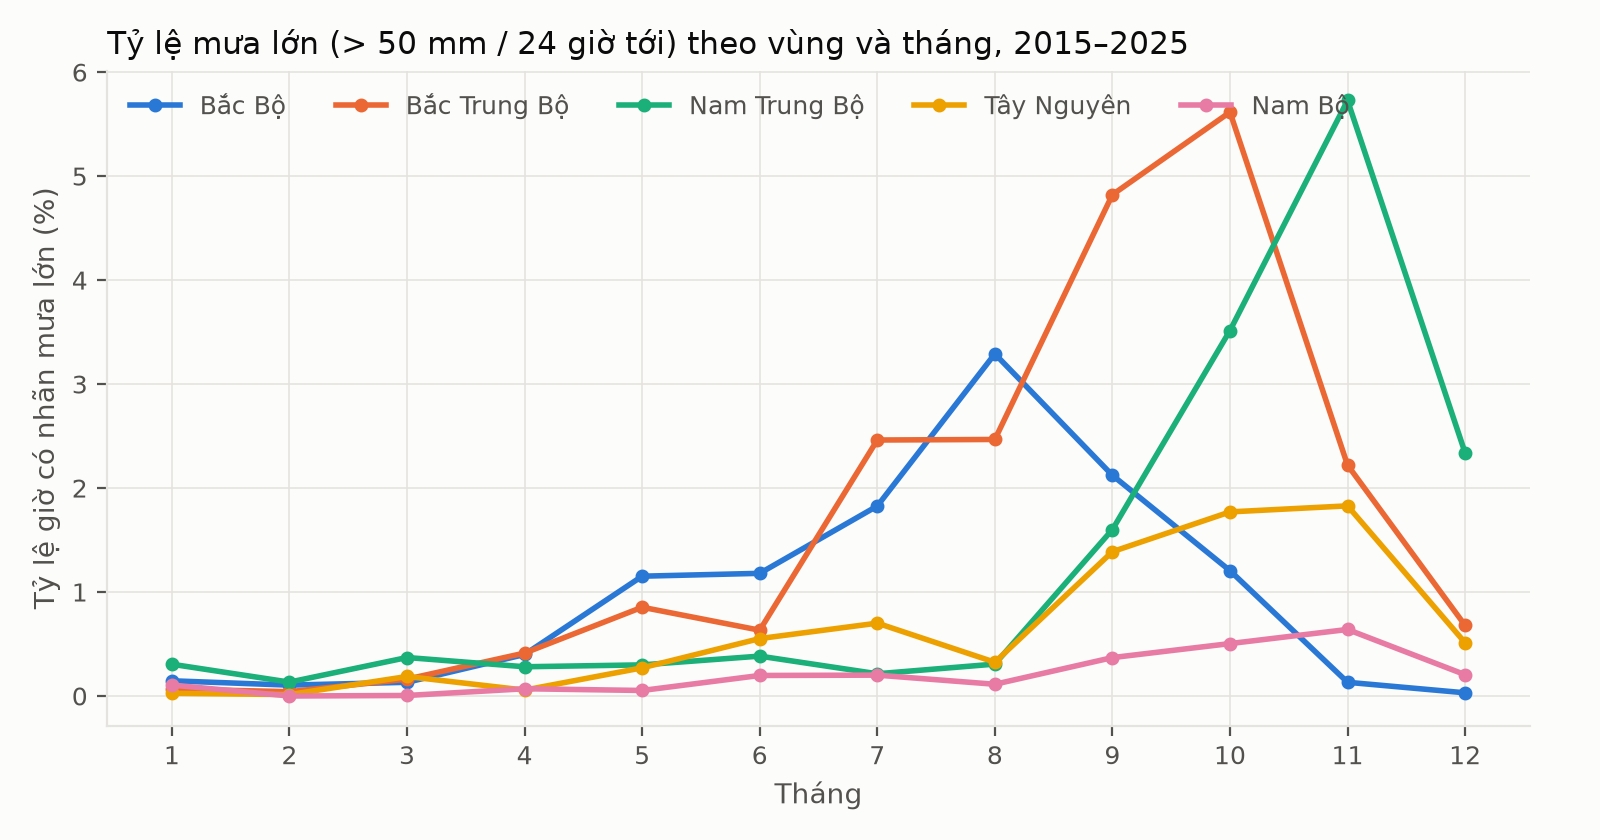

region,Bac,BacTrungBo,Nam,NamTrungBo,TayNguyen
month,,,,,
1,0.1500,0.0700,0.1100,0.3100,0.0300
2,0.1000,0.0400,0.0000,0.1300,0.0100
3,0.1300,0.1600,0.0000,0.3700,0.1900
4,0.4000,0.4100,0.0700,0.2800,0.0600
5,1.1500,0.8500,0.0500,0.3000,0.2700
6,1.1800,0.6300,0.2000,0.3800,0.5500
7,1.8300,2.4600,0.2000,0.2100,0.7000
8,3.2900,2.4700,0.1100,0.3100,0.3200
9,2.1200,4.8200,0.3700,1.6000,1.3900


In [9]:
rm = eda.label_rates(gold, ['region', 'month'])
eda.fig_region_month(rm, OUT / 'fig_label_region_month.png')
display(Image(OUT / 'fig_label_region_month.png', width=820))
rm.pivot(index='month', columns='region', values='positive_rate').mul(100).round(2)

## 8. Phân bố không gian: theo ô và theo tỉnh mới

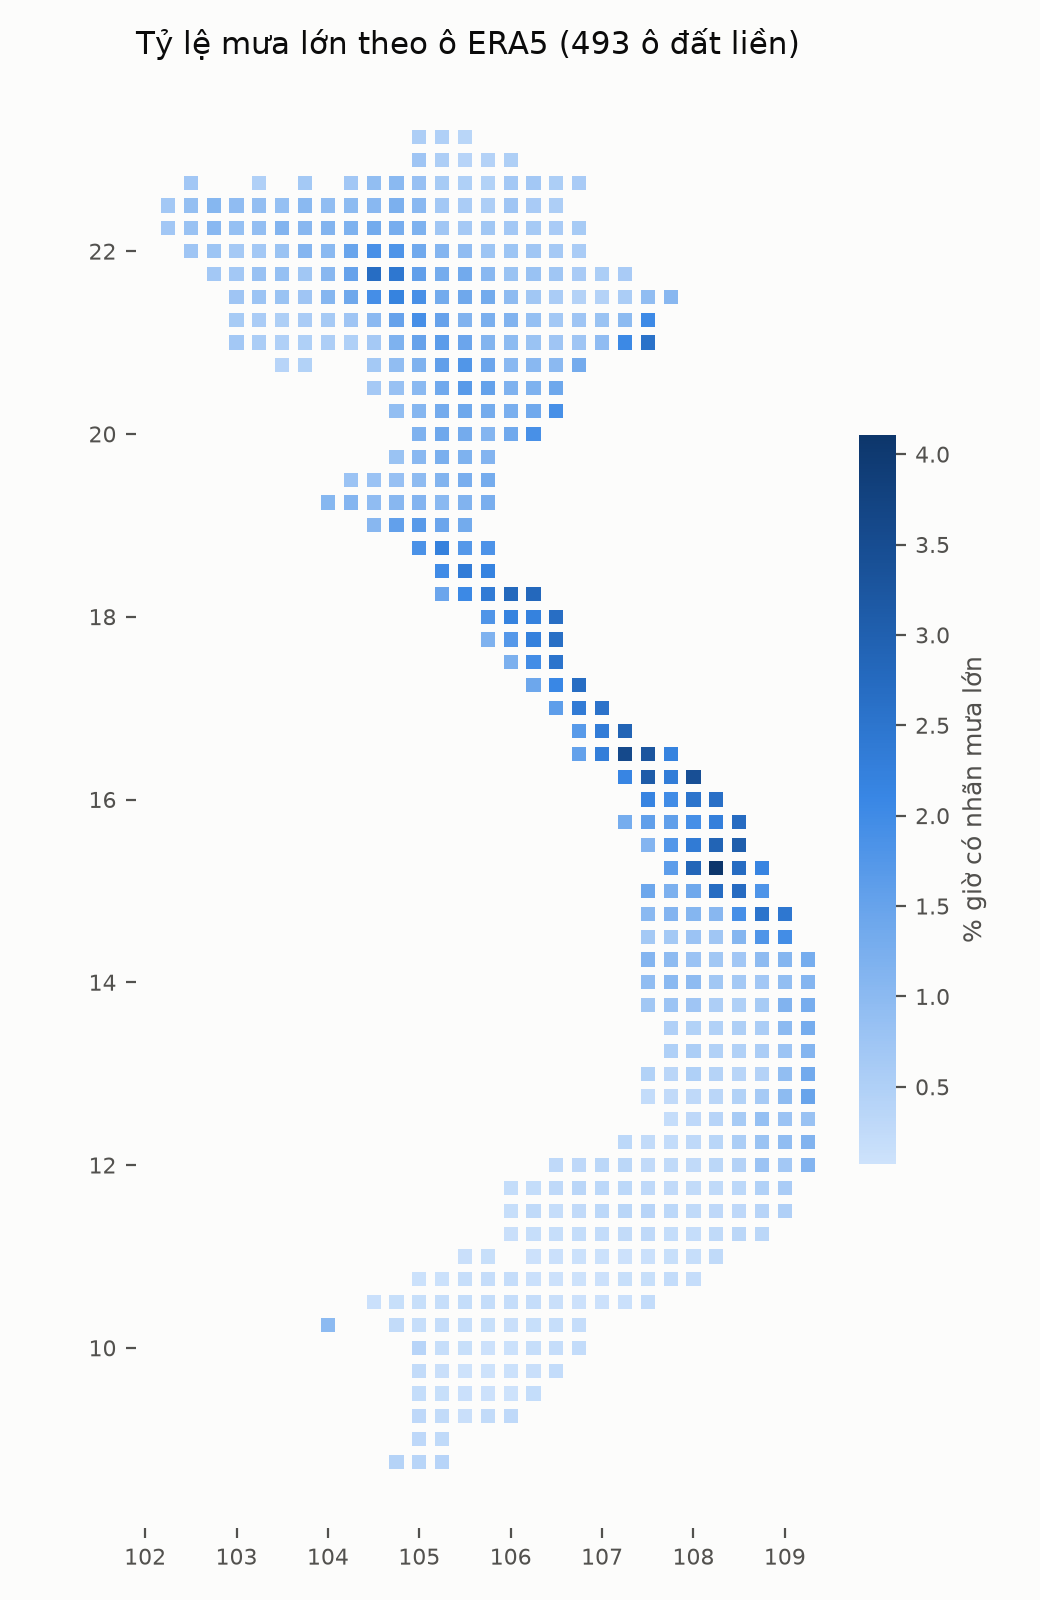

In [10]:
by_cell = eda.label_rates(gold, ['location_id', 'lat', 'lon', 'new_province', 'region'])
eda.fig_map(by_cell, OUT / 'fig_label_map.png')
display(Image(OUT / 'fig_label_map.png', width=420))

In [11]:
by_prov = eda.label_rates(gold, ['new_province']).sort_values('positive_rate', ascending=False)
by_prov.head(15)

,new_province,rows,positives,positive_rate
6,Huế,674856,"19,330.0000",0.0286
30,Đà Nẵng,1638936,"37,502.0000",0.0229
8,Hà Tĩnh,867672,"19,486.0000",0.0225
21,Quảng Trị,2024568,"42,081.0000",0.0208
18,Phú Thọ,1446120,"22,228.0000",0.0154
19,Quảng Ngãi,2217384,"33,596.0000",0.0152
17,Ninh Bình,578448,"8,586.0000",0.0148
13,Lào Cai,1831752,"26,627.0000",0.0145
20,Quảng Ninh,771264,"10,985.0000",0.0142
16,Nghệ An,2410200,"29,953.0000",0.0124


## 9. Theo năm

In [12]:
by_year = eda.label_rates(gold, ['year'])
by_year

,year,rows,positives,positive_rate
0,2015,4318680,"25,643.0000",0.0059
1,2016,4330512,"38,458.0000",0.0089
2,2017,4318680,"42,499.0000",0.0098
3,2018,4318680,"34,809.0000",0.0081
4,2019,4318680,"32,943.0000",0.0076
5,2020,4330512,"52,910.0000",0.0122
6,2021,4318680,"46,396.0000",0.0107
7,2022,4318680,"39,511.0000",0.0091
8,2023,4318680,"28,683.0000",0.0066
9,2024,4330512,"48,007.0000",0.0111


## 10. Tương quan feature với nhãn (train)
M1 = khí tượng bề mặt (24 feature), M4 = khí quyển (9 feature từ 6 biến mới).

In [13]:
corr = eda.feature_corr(gold)
corr

,feature,group,corr_with_label,null_rate
0,rain_3h,M1,0.2786,0.0000
29,vimd_sum_6h,M4,-0.2592,0.0001
1,rain_24h,M1,0.2358,0.0003
2,rain_72h,M1,0.1671,0.0010
26,ivt,M4,0.1607,0.0000
3,rain_max_1h_24h,M1,0.1426,0.0003
4,rain_hours_24h,M1,0.1361,0.0003
24,tcwv,M4,0.1005,0.0000
25,tcwv_change_24h,M4,0.0979,0.0003
19,cloud_mean_6h,M1,0.0749,0.0001


## 11. Đối chiếu với Open-Meteo tại 63 điểm
Cùng nguồn ERA5; tương quan cao nhất ở độ lệch 0 giờ xác nhận đổi UTC → giờ VN đúng.

In [14]:
cc = eda.crosscheck(spark, cfg, silver, cells)
if cc is not None:
    res, lags = cc
    display(pd.Series(lags, name='hourly precip corr'))
    display(res.describe())

26/11/07 10:31:23 WARN FileStreamSink: Assume no metadata directory. Error while looking for metadata directory in the path: /app/data/raw/era5/grid=*/year=*.json.
java.io.FileNotFoundException: File /app/data/raw/era5/grid=*/year=*.json does not exist
	at org.apache.hadoop.fs.RawLocalFileSystem.deprecatedGetFileStatus(RawLocalFileSystem.java:980)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileLinkStatusInternal(RawLocalFileSystem.java:1301)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileStatus(RawLocalFileSystem.java:970)
	at org.apache.hadoop.fs.FilterFileSystem.getFileStatus(FilterFileSystem.java:462)
	at org.apache.spark.sql.execution.streaming.sinks.FileStreamSink$.hasMetadata(FileStreamSink.scala:58)
	at org.apache.spark.sql.execution.datasources.DataSource.resolveRelation(DataSource.scala:394)
	at org.apache.spark.sql.catalyst.analysis.ResolveDataSource.org$apache$spark$sql$catalyst$analysis$ResolveDataSource$$loadV1BatchSource(ResolveDataSource.scala:210)
	at org.apache

corr_lag_-1h   0.6980
corr_lag_+0h   0.9889
corr_lag_+1h   0.6984
Name: hourly precip corr, dtype: float64

,hours,hourly_precip_corr,temp_bias_c,temp_mae_c,daily_precip_corr,precip_ratio_cds_over_om
count,63.0000,63.0000,63.0000,63.0000,63.0000,63.0000
mean,"96,432.0000",0.9866,-0.2006,0.4549,0.9940,1.0254
std,0.0000,0.0518,0.7412,0.6482,0.0234,0.0438
min,"96,432.0000",0.7450,-3.3250,0.0314,0.8788,0.7982
25%,"96,432.0000",0.9994,-0.3251,0.0318,0.9997,1.0273
50%,"96,432.0000",0.9996,-0.0303,0.1254,0.9998,1.0297
75%,"96,432.0000",0.9996,0.0246,0.7003,0.9999,1.0328
max,"96,432.0000",0.9997,1.9249,3.3250,0.9999,1.1409


## 12. Ghi kết quả và trang báo cáo
Ghi CSV/JSON như bước EDA của pipeline, rồi dựng trang HTML và chụp ảnh từng phần bằng Playwright.

In [15]:
(OUT / 'volume.json').write_text(json.dumps({**vol, **({'crosscheck_openmeteo': {
    'points': len(res), 'median_daily_precip_corr': float(res.daily_precip_corr.median()),
    'median_hourly_precip_corr': float(res.hourly_precip_corr.median()),
    'median_temp_bias_c': float(res.temp_bias_c.median()), **lags}} if cc is not None else {})},
    indent=2, ensure_ascii=False), encoding='utf-8')
q.to_csv(OUT / 'precip_quantiles.csv', index=False)
by_split.to_csv(OUT / 'label_by_split.csv', index=False)
rm.to_csv(OUT / 'label_by_region_month.csv', index=False)
by_cell.to_csv(OUT / 'label_by_cell.csv', index=False)
by_prov.to_csv(OUT / 'label_by_new_province.csv', index=False)
by_year.to_csv(OUT / 'label_by_year.csv', index=False)
corr.to_csv(OUT / 'feature_label_corr.csv', index=False)
if cc is not None: res.to_csv(OUT / 'crosscheck_openmeteo.csv', index=False)
from src.analytics import eda_report
page = OUT / 'eda_report.html'
page.write_text(eda_report.build_html(), encoding='utf-8')
try:  # Playwright có trên máy; trong container chỉ ghi HTML
    print(eda_report.screenshot(page, OUT / 'screens'))
except ImportError:
    print('Đã ghi', page, '- chụp ảnh trên máy: .venv/Scripts/python.exe -m src.analytics.eda_report')

Đã ghi /app/reports/official/eda/eda_report.html - chụp ảnh trên máy: .venv/Scripts/python.exe -m src.analytics.eda_report


In [16]:
spark.stop()